<a href="https://colab.research.google.com/github/Janani-hari/BMSCE-DATA-VISUALIZATION/blob/main/Data_Visulization_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Raw Dataset Shape: (1994, 128)
Columns with missing values: 25
Cleaned Dataset Shape: (1994, 104) | Remaining Nulls: 0



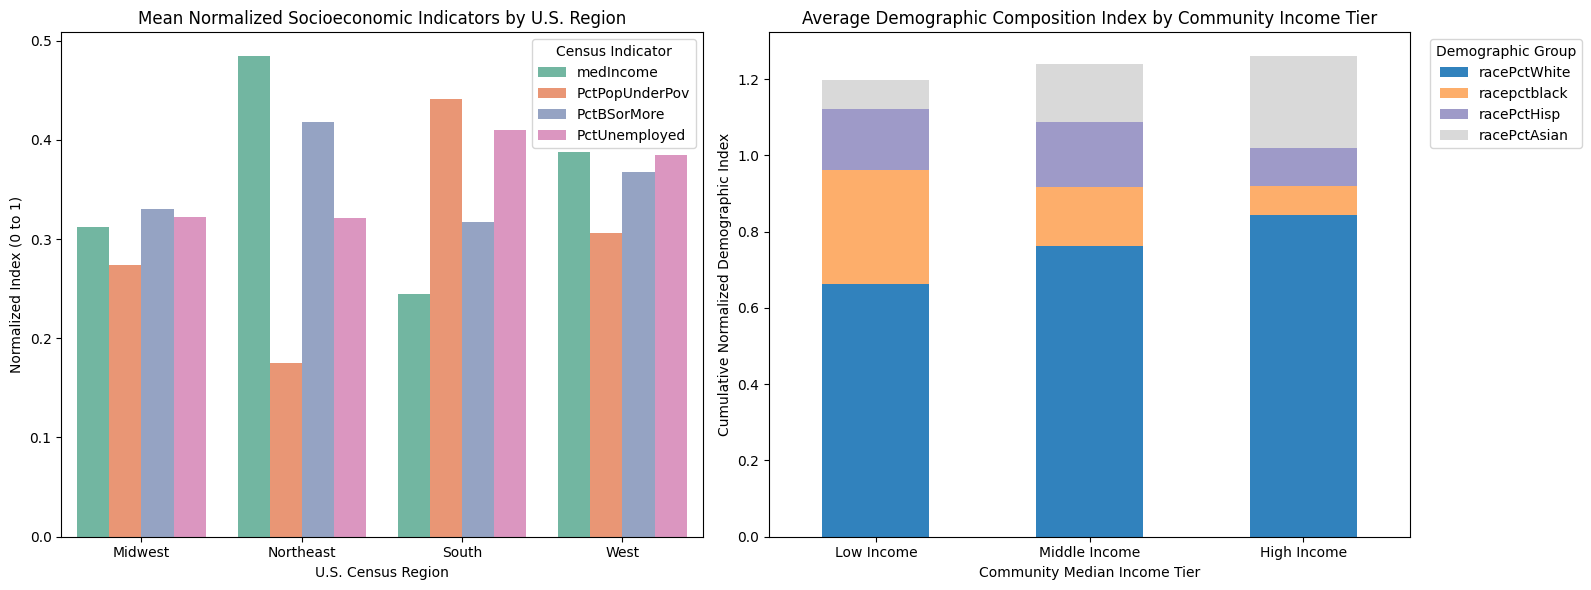

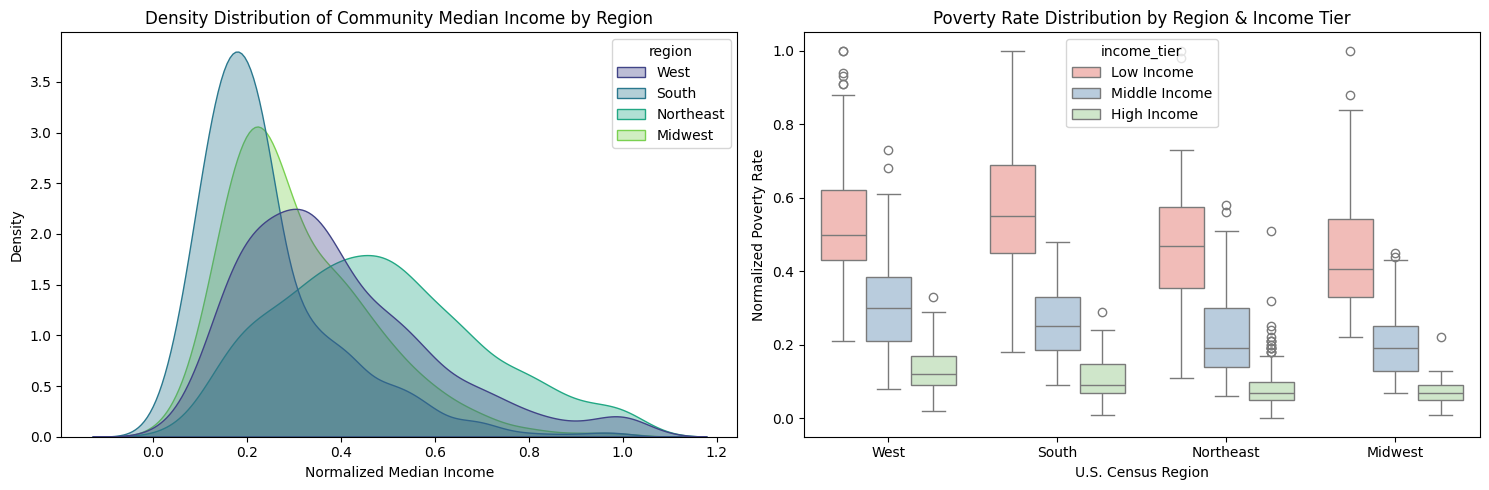

/usr/local/lib/python3.13/dist-packages/plotly/express/_core.py:1727: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  dfg = df.groupby(path[i:]).agg(agg_f)


In [1]:
# ==========================================
# TASK 5: Spatial & Demographic Census Analysis (Google Colab)
# Dataset: UCI Communities and Crime Census Dataset (Direct URL)
# ==========================================
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.preprocessing import MinMaxScaler, StandardScaler

# 1. Fetch official attribute names and census data directly from UCI Repository
names_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/communities/communities.names"
data_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/communities/communities.data"

raw_names = urllib.request.urlopen(names_url).read().decode("utf-8").splitlines()
col_names = [line.split()[1] for line in raw_names if line.startswith("@attribute")]

df_raw = pd.read_csv(data_url, header=None, names=col_names, na_values=["?"])
print(f"Raw Dataset Shape: {df_raw.shape}")

# 2. Handle Missing Values
# Inspect columns with missing values
missing_counts = df_raw.isnull().sum()
print("Columns with missing values:", len(missing_counts[missing_counts > 0]))

# Drop sparse administrative/LEMAS columns (>50% missing) and impute remaining numeric gaps with median
threshold = len(df_raw) * 0.5
df_clean = df_raw.dropna(axis=1, thresh=threshold).copy()

numeric_cols = df_clean.select_dtypes(include=[np.number]).columns.tolist()
for col in numeric_cols:
    if df_clean[col].isnull().sum() > 0:
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

print(f"Cleaned Dataset Shape: {df_clean.shape} | Remaining Nulls: {df_clean.isnull().sum().sum()}\n")

# 3. Map FIPS State Codes to U.S. State Abbreviations & Census Regions
fips_to_state = {
    1: "AL", 2: "AK", 4: "AZ", 5: "AR", 6: "CA", 8: "CO", 9: "CT", 10: "DE",
    11: "DC", 12: "FL", 13: "GA", 15: "HI", 16: "ID", 17: "IL", 18: "IN",
    19: "IA", 20: "KS", 21: "KY", 22: "LA", 23: "ME", 24: "MD", 25: "MA",
    26: "MI", 27: "MN", 28: "MS", 29: "MO", 30: "MT", 31: "NE", 32: "NV",
    33: "NH", 34: "NJ", 35: "NM", 36: "NY", 37: "NC", 38: "ND", 39: "OH",
    40: "OK", 41: "OR", 42: "PA", 44: "RI", 45: "SC", 46: "SD", 47: "TN",
    48: "TX", 49: "UT", 50: "VT", 51: "VA", 53: "WA", 54: "WV", 55: "WI", 56: "WY"
}

state_to_region = {
    "CT": "Northeast", "ME": "Northeast", "MA": "Northeast", "NH": "Northeast",
    "RI": "Northeast", "VT": "Northeast", "NJ": "Northeast", "NY": "Northeast", "PA": "Northeast",
    "IL": "Midwest", "IN": "Midwest", "MI": "Midwest", "OH": "Midwest", "WI": "Midwest",
    "IA": "Midwest", "KS": "Midwest", "MN": "Midwest", "MO": "Midwest", "NE": "Midwest",
    "ND": "Midwest", "SD": "Midwest",
    "DE": "South", "FL": "South", "GA": "South", "MD": "South", "NC": "South",
    "SC": "South", "VA": "South", "DC": "South", "WV": "South", "AL": "South",
    "KY": "South", "MS": "South", "TN": "South", "AR": "South", "LA": "South",
    "OK": "South", "TX": "South",
    "AZ": "West", "CO": "West", "ID": "West", "MT": "West", "NV": "West",
    "NM": "West", "UT": "West", "WY": "West", "AK": "West", "CA": "West",
    "HI": "West", "OR": "West", "WA": "West"
}

df_clean["state_abbr"] = df_clean["state"].map(fips_to_state)
df_clean["region"] = df_clean["state_abbr"].map(state_to_region)
df_clean["income_tier"] = pd.qcut(
    df_clean["medIncome"], q=3, labels=["Low Income", "Middle Income", "High Income"]
)

# 4. Normalize Key Demographic & Socioeconomic Fields (Min-Max & Z-Score)
demo_features = [
    "medIncome", "PctPopUnderPov", "PctBSorMore",
    "PctUnemployed", "pctUrban", "agePct65up", "ViolentCrimesPerPop"
]
minmax = MinMaxScaler()
zscore = StandardScaler()

df_minmax = pd.DataFrame(
    minmax.fit_transform(df_clean[demo_features]),
    columns=[f"{c}_minmax" for c in demo_features]
)
df_zscore = pd.DataFrame(
    zscore.fit_transform(df_clean[demo_features]),
    columns=[f"{c}_zscore" for c in demo_features]
)
df_final = pd.concat([df_clean, df_minmax, df_zscore], axis=1)

# 5. Demographic Charts: Regional Socioeconomic & Racial Composition
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Chart A: Mean Normalized Socioeconomic Indicators by U.S. Region
region_socio = (
    df_final.groupby("region")[["medIncome", "PctPopUnderPov", "PctBSorMore", "PctUnemployed"]]
    .mean()
    .reset_index()
    .melt(id_vars="region", var_name="Indicator", value_name="Mean_Normalized_Score")
)
sns.barplot(
    data=region_socio, x="region", y="Mean_Normalized_Score",
    hue="Indicator", palette="Set2", ax=axes[0]
)
axes[0].set_title("Mean Normalized Socioeconomic Indicators by U.S. Region")
axes[0].set_xlabel("U.S. Census Region")
axes[0].set_ylabel("Normalized Index (0 to 1)")
axes[0].legend(title="Census Indicator")

# Chart B: Average Demographic Composition Across Income Tiers
race_cols = ["racePctWhite", "racepctblack", "racePctHisp", "racePctAsian"]
tier_demo = (
    df_final.groupby("income_tier", observed=False)[race_cols]
    .mean()
)
tier_demo.plot(kind="bar", stacked=True, colormap="tab20c", ax=axes[1])
axes[1].set_title("Average Demographic Composition Index by Community Income Tier")
axes[1].set_xlabel("Community Median Income Tier")
axes[1].set_ylabel("Cumulative Normalized Demographic Index")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Demographic Group", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

# 6. Distribution Plots: Median Income & Poverty Rate Across Regions
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.kdeplot(
    data=df_final, x="medIncome", hue="region",
    fill=True, common_norm=False, alpha=0.35, palette="viridis", ax=axes[0]
)
axes[0].set_title("Density Distribution of Community Median Income by Region")
axes[0].set_xlabel("Normalized Median Income")

sns.boxplot(
    data=df_final, x="region", y="PctPopUnderPov",
    hue="income_tier", palette="Pastel1", ax=axes[1]
)
axes[1].set_title("Poverty Rate Distribution by Region & Income Tier")
axes[1].set_xlabel("U.S. Census Region")
axes[1].set_ylabel("Normalized Poverty Rate")

plt.tight_layout()
plt.show()

# 7. Hierarchical Treemap (Region -> State -> Community Income Tier)
treemap_df = (
    df_final.groupby(["region", "state_abbr", "income_tier"], observed=False)
    .agg(
        community_count=("communityname", "count"),
        avg_poverty=("PctPopUnderPov", "mean")
    )
    .reset_index()
)
treemap_df = treemap_df[treemap_df["community_count"] > 0]

fig_treemap = px.treemap(
    treemap_df,
    path=[px.Constant("U.S. Census Communities"), "region", "state_abbr", "income_tier"],
    values="community_count",
    color="avg_poverty",
    color_continuous_scale="RdYlBu_r",
    title="Spatial-Demographic Treemap: Region → State → Income Tier (Colored by Poverty Index)"
)
fig_treemap.update_traces(textinfo="label+value")
fig_treemap.show()

# 8. Interactive Geospatial Map (U.S. State-Level Choropleth)
state_geo = (
    df_final.groupby("state_abbr")
    .agg(
        communities=("communityname", "count"),
        avg_med_income=("medIncome", lambda s: round(s.mean(), 3)),
        avg_poverty_idx=("PctPopUnderPov", lambda s: round(s.mean(), 3)),
        avg_bachelors_idx=("PctBSorMore", lambda s: round(s.mean(), 3)),
        avg_violent_crime=("ViolentCrimesPerPop", lambda s: round(s.mean(), 3))
    )
    .reset_index()
)

fig_map = px.choropleth(
    state_geo,
    locations="state_abbr",
    locationmode="USA-states",
    scope="usa",
    color="avg_med_income",
    hover_name="state_abbr",
    hover_data={
        "communities": True,
        "avg_poverty_idx": True,
        "avg_bachelors_idx": True,
        "avg_violent_crime": True,
        "state_abbr": False
    },
    color_continuous_scale="YlGnBu",
    title="Interactive U.S. Geospatial Map: State-Level Median Income & Socioeconomic Indicators"
)
fig_map.show()